# 2D Taylor-Green

In [1]:
import numpy as np
import matplotlib.pylab as plt
import matplotlib.colors
from IPython.display import display, Math, Latex
import time
Nx=40
Ny=Nx
# ---------------------------Lattice-Properties--------------------------------------------
w0=4.0/9.0;w1=1.0/9.0;w2=1.0/36.0; # Lattice Weights
w = np.array([w0,w1,w1,w1,w1,w2,w2,w2,w2],dtype="float64") 
cx = np.array([0,1,0,-1, 0,1,-1,-1, 1],dtype="int8")  # Lattice Directions
cy = np.array([0,0,1, 0,-1,1, 1,-1,-1],dtype="int8")  # Lattice Directions
# opp = np.array([0,3,4,1,2,7,8,5,6],dtype="uint8")  # Opposite Lattice Directions
#------------Dimensionless Parameter For Pro----------------
uo = 1.0 # Dimensionless Velocity
ho = 1.0 # Dimensionless Domain Length
Re = 30.0 # Reynolds Number
nuo = uo*ho/Re #Dimensionless Kinematic Viscosity
#------------------------------------------Scaling Term--------------------------------------------
dx = ho / (Nx) # Grid size 
r = 2.0**(3) # Relation term r=dx/dt
dt = dx / r # Time Step
#----------------------------------------LBM-Scale-----------------------------------------------
nu = dt * nuo / (dx * dx)  #Scaling Viscosity
ue = dt * uo / dx  #Scaling Velocity
cs = 1.0 / np.sqrt(3.) #Sound Speed
tau = (nu/ (cs * cs)) + (1.0/ 2.0) #Relaxation time
rhoi = 1.0 #Initial Densty
mstep=10
#--------------Print-Data-------------------------------------------------------------------------
display(Math(r"\tau="+str(tau)+r"\quad\quad \nu="+str(nu)))
display(Math(r"r="+str(r)+r"\quad\quad \overline{u}="+str(ue)))
display(Math(r"dx="+str(dx)+r"\quad\quad dt="+str(dt)))
#---------------------Field-Arrays---------------------------------------------------------------- 
Mass=np.zeros((mstep),dtype="float64") # Allocating Density field
Enr=np.zeros((mstep),dtype="float64") # Allocating Density field
rho=np.zeros((Nx,Ny),dtype="float64") # Allocating Density field
Vx=np.zeros((Nx,Ny),dtype="float64") # Allocating Null Velocity x Field
Vy=np.zeros((Nx,Ny),dtype="float64") # Allocating Null Velocity y Field
# ----------------------------Init Field------------------------------------------------------
xi = np.arange(Nx, dtype="float64") + 0.5
yi = np.arange(Ny, dtype="float64") + 0.5
Xi, Yi = np.meshgrid(xi, yi, indexing="ij")
rho = rhoi - (rhoi * ue**2 / (4.0 * cs**2)) * (np.cos(4.0 * np.pi * Xi / Nx) + np.cos(4.0 * np.pi * Yi / Ny))    # Density
Vx = -ue * (np.cos(2.0 * np.pi * Xi / Nx) * np.sin(2.0 * np.pi * Yi / Ny)) # Velocity X
Vy = ue * (np.cos(2.0 * np.pi * Yi / Ny) * np.sin(2.0 * np.pi * Xi / Nx)) # Velocity Y
#----------------Initializing Distribution Functions----------------
f=np.zeros((9,Nx,Ny),dtype="float64") # Allocating Pre-Collisional Distribution Function
fp=np.zeros((9,Nx,Ny),dtype="float64") # Allocating Pos-Collisional Distribution Function
feq=np.zeros((9,Nx,Ny),dtype="float64") # Allocating Pos-Collisional Distribution Function
for k in range (0,9):
    f[k,:,:]=w[k]*rho*(1. + 3.*(Vx*cx[k]+Vy*cy[k]) + 4.5*(Vx*cx[k]+Vy*cy[k])**2-1.5*(Vx*Vx+Vy*Vy))
#---------------------------------Main-Loop-------------------------------------------------------
En=0.0; 
start=time.time()
for kk in range(0,mstep):
    #------------------------------------Collision-----------------------------------------------------------------------------
    for k in range(0,9):
        feq[k,:,:]=w[k]*rho*(1. + 3.*(Vx*cx[k]+Vy*cy[k]) + 4.5*(Vx*cx[k]+Vy*cy[k])**2-1.5*(Vx*Vx+Vy*Vy))
        # feq[k,:,:]=w[k]*rho*(1.0 + 3.0*(Vx*cx[k]+Vy*cy[k]) + 4.5*(Vx*cx[k]*Vx*cx[k]) - 1.5*(Vx*Vx+Vy*Vy))
        # feq[k,:,:]=w[k]*rho*(1.0 + 3.0*(Vx*cx[k]+Vy*cy[k]) - 1.5*(Vx*Vx+Vy*Vy))
        fp[k,:,:]=f[k,:,:]-(1.0/tau)*(f[k,:,:]-feq[k,:,:])
    #----------------------------------Streaming---------------------------------------------------------------------------
    for k in range(0,9):
        f[k,:,:]=np.roll(np.roll(fp[k,:,:], cx[k], axis=0), cy[k], axis=1)
    #--------------------------------------Macro-Properties------------------------------------------------------------------
    rho=np.einsum('ixy->xy', f)
    Vx=np.einsum('i,ixy->xy', cx, f)/rho
    Vy=np.einsum('i,ixy->xy', cy, f)/rho
    #-------------------------------------Convergence------------------------------------------------------------------------
    Mass[kk] = np.sum(rho)/(Nx*Ny)
    Umed = np.sum(np.abs(Vx))/(Nx*Ny)
    print('|Umed|=',np.fabs(Umed) )
    Enr[kk]=Umed

/home/ricardolmb/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

|Umed|= 0.050342063932128284
|Umed|= 0.049917957859596046
|Umed|= 0.04949411065377911
|Umed|= 0.049072206220411536
|Umed|= 0.04865393285883249
|Umed|= 0.048240850198540956
|Umed|= 0.047834272177555655
|Umed|= 0.04743517598507372
|Umed|= 0.04704414435976784
|Umed|= 0.046661345203976336


Da= 2.2671267902787555 	 Diff= 5.24469356832924e-13 	 Umed= 0.030755661960068757 	 Erro= 0.1328732097212444
Da= 2.267126790279089 	 Diff= 3.33510996597397e-13 	 Umed= 0.030755661960068688 	 Erro= 0.13287320972091088
Da= 2.267126790279118 	 Diff= 2.886579864025407e-14 	 Umed= 0.030755661960068716 	 Erro= 0.132873209720882
Da= 2.2671267902794248 	 Diff= 3.0686564400639327e-13 	 Umed= 0.030755661960068785 	 Erro= 0.13287320972057515
Da= 2.267126790279061 	 Diff= 3.637090628672013e-13 	 Umed= 0.030755661960068716 	 Erro= 0.13287320972093886
Da= 2.267126790278939 	 Diff= 1.2212453270876722e-13 	 Umed= 0.030755661960068667 	 Erro= 0.13287320972106098
Da= 2.267126790278952 	 Diff= 1.2878587085651816e-14 	 Umed= 0.030755661960068757 	 Erro= 0.1328732097210481
Da= 2.2671267902792893 	 Diff= 3.375077994860476e-13 	 Umed= 0.030755661960068636 	 Erro= 0.1328732097207106
Da= 2.2671267902792813 	 Diff= 7.993605777301127e-15 	 Umed= 0.030755661960068705 	 Erro= 0.1328732097207186
Da= 2.26712679027908

Text(0, 0.5, '$Y$')

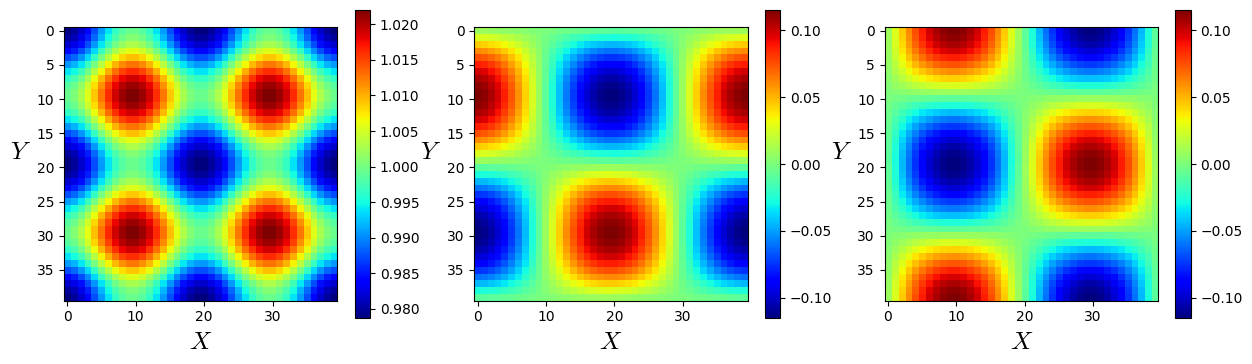

In [2]:
matplotlib.rcParams['mathtext.fontset'] = 'cm'
fig1, (ax1,ax2,ax3) = plt.subplots(ncols=3,figsize=(15,4))
img1=ax1.imshow(np.rot90(rho[:,:]),cmap='jet', interpolation='none')
fig1.colorbar(img1, ax=ax1)
ax1.set_xlabel('$X$',fontsize=18)
ax1.set_ylabel('$Y$',fontsize=18,horizontalalignment='right',rotation=0)
img2=ax2.imshow(np.rot90(Vx[:,:]),cmap='jet', interpolation='none')
fig1.colorbar(img2, ax=ax2)
ax2.set_xlabel('$X$',fontsize=18)
ax2.set_ylabel('$Y$',fontsize=18,horizontalalignment='right',rotation=0) 
img3=ax3.imshow(np.rot90(Vy[:,:]),cmap='jet', interpolation='none')
fig1.colorbar(img3, ax=ax3)
ax3.set_xlabel('$X$',fontsize=18)
ax3.set_ylabel('$Y$',fontsize=18,horizontalalignment='right',rotation=0) 

In [3]:
print(Enr[:])

[0.05034206 0.04991796 0.04949411 0.04907221 0.04865393 0.04824085
 0.04783427 0.04743518 0.04704414 0.04666135]


Text(0.5, 0, '$t$')

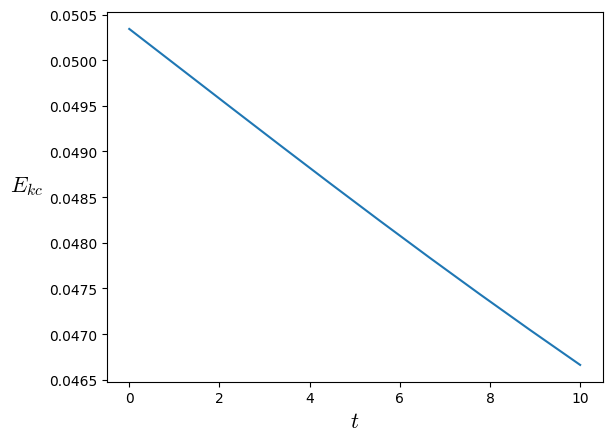

In [4]:
plt.plot(np.linspace(0,len(Enr),len(Enr)),Enr)
plt.ylabel('$E_{kc}$',fontsize=16,rotation=0,horizontalalignment='right')
plt.xlabel('$t$',fontsize=16)

Text(0.5, 0, '$t$')

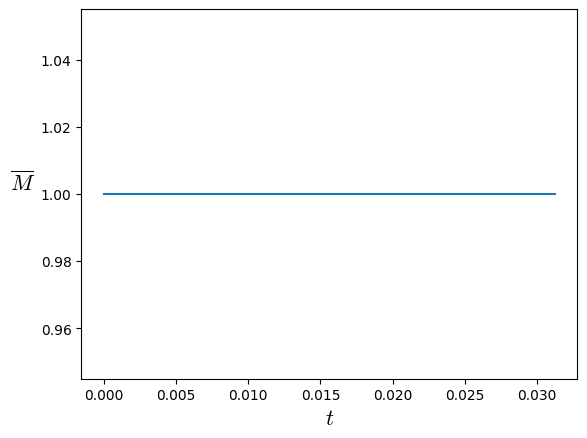

In [5]:
plt.plot(np.linspace(0,len(Mass),len(Mass))/Nx/r,Mass)
plt.ylabel('$\overline{M}$',fontsize=16,rotation=0,horizontalalignment='right')
plt.xlabel('$t$',fontsize=16)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math
import time
# --------------------------- Domain ---------------------------
Nx = 40
Ny = Nx
mstep = 1000
# ---------------------- Lattice properties --------------------
# Choose a constant reference sound speed:
cs = 1.0 / np.sqrt(3.0)         # Standard D2Q9
# cs = 1.0 / np.sqrt(4.0 / 3.0)  # Your previous choice: cs² = 3/4
cs2 = cs**2
if not 0.0 < cs2 < 1.0:
    raise ValueError("Require 0 < cs² < 1 for positive lattice weights.")
# Weight PER velocity
w0 = (1.0 - cs2)**2
w1 = cs2 * (1.0 - cs2) / 2.0
w2 = cs2**2 / 4.0
w = np.array([w0, w1, w1, w1, w1, w2, w2, w2, w2], dtype=np.float64 )
cx = np.array([0, 1, 0, -1, 0, 1, -1, -1, 1], dtype=int)
cy = np.array([0, 0, 1, 0, -1, 1, 1, -1, -1], dtype=int)
# Shapes (9, 1, 1), for broadcasting over the spatial grid
W = w[:, None, None]
CX = cx[:, None, None]
CY = cy[:, None, None]
# ------------------ Dimensionless parameters ------------------
uo = 1.0
ho = 1.0
Re = 30.0
nuo = uo * ho / Re
# --------------------------- Scaling --------------------------
dx = ho / Nx
r = 2.0**3                     # Velocity conversion: dx/dt
dt = dx / r
nu = dt * nuo / dx**2
ue = dt * uo / dx
# Sets the off-diagonal shear viscosity.
# For cs² != 1/3, BGK does not generally give isotropic viscosity.
tau = nu / cs2 + 0.5
rhoi = 1.0
display(Math(rf"c_s^2={cs2:.6g},\quad " rf"w_0={w0:.6g},\quad w_1={w1:.6g},\quad w_2={w2:.6g}" ))
display(Math(rf"\tau={tau:.6g},\quad \nu={nu:.6g}"))
display(Math(rf"r={r:.6g},\quad \overline{{u}}={ue:.6g}"))
display(Math(rf"\Delta x={dx:.6g},\quad \Delta t={dt:.6g}"))
# ------------------- Corrected equilibrium --------------------
def equilibrium(rho, ux, uy):
    """D2Q9 equilibrium with exact prescribed moments through order 2."""
    linear = (CX * ux + CY * uy) / cs2
    diagonal = (ux**2 * (CX**2 - cs2) + uy**2 * (CY**2 - cs2) ) / (cs2 * (1.0 - cs2))
    mixed = ux * uy * CX * CY / cs2**2
    return W * rho * (1.0 + linear + diagonal + mixed)
# ------------------------- Initial fields ---------------------
xi = np.arange(Nx, dtype=np.float64) + 0.5
yi = np.arange(Ny, dtype=np.float64) + 0.5
Xi, Yi = np.meshgrid(xi, yi, indexing="ij")
rho = rhoi - (rhoi * ue**2 / (4.0 * cs2)) * ( np.cos(4.0 * np.pi * Xi / Nx) + np.cos(4.0 * np.pi * Yi / Ny) )
Vx = -ue * (np.cos(2.0 * np.pi * Xi / Nx) * np.sin(2.0 * np.pi * Yi / Ny) )
Vy = ue * (np.cos(2.0 * np.pi * Yi / Ny) * np.sin(2.0 * np.pi * Xi / Nx) )
if np.any(rho <= 0.0):
    raise ValueError("Initial density is nonpositive; reduce ue/cs.")
# ------------------- Initialize populations -------------------
f = equilibrium(rho, Vx, Vy)
# Verify the six equilibrium moment constraints
checks = {
    "density": (np.sum(f, axis=0), rho),
    "momentum x": (np.sum(CX * f, axis=0), rho * Vx),
    "momentum y": (np.sum(CY * f, axis=0), rho * Vy),
    "second moment xx": (np.sum(CX**2 * f, axis=0), rho * (cs2 + Vx**2) ),
    "second moment xy": (np.sum(CX * CY * f, axis=0), rho * Vx * Vy ),
    "second moment yy": (np.sum(CY**2 * f, axis=0), rho * (cs2 + Vy**2) ),
}

for name, (actual, expected) in checks.items():
    np.testing.assert_allclose(actual, expected, rtol=1e-12, atol=1e-13,err_msg=name)
# -------------------------- Diagnostics -----------------------
Mass = np.zeros(mstep)
Enr = np.zeros(mstep)  # Retains your mean |ux| diagnostic; not energy
initial_mass = np.mean(rho)
# --------------------------- Main loop ------------------------
start = time.perf_counter()
for kk in range(mstep):
    # Collision
    feq = equilibrium(rho, Vx, Vy)
    fp = f - (f - feq) / tau
    # Periodic streaming
    for k in range(9):
        f[k] = np.roll(fp[k],shift=(int(cx[k]), int(cy[k])), axis=(0, 1) )
    # Macroscopic properties
    rho = np.sum(f, axis=0)
    if not np.all(np.isfinite(f)) or np.any(rho <= 0.0):
        raise FloatingPointError(f"Invalid populations or density at step {kk + 1}.")
    Vx = np.einsum("i,ixy->xy", cx, f) / rho
    Vy = np.einsum("i,ixy->xy", cy, f) / rho
    Mass[kk] = np.mean(rho)
    Enr[kk] = np.mean(np.abs(Vx))
    # print(f"step={kk + 1:4d}, mean |ux|={Enr[kk]:.8e}")

elapsed = time.perf_counter() - start
mass_drift = np.max(np.abs(Mass - initial_mass)) / initial_mass

print(f"Elapsed time: {elapsed:.3f} s")
print(f"Maximum relative mass drift: {mass_drift:.3e}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Elapsed time: 0.200 s
Maximum relative mass drift: 9.726e-14


cs²=0.100000, Ma0=0.197642, tau=0.679167, td=2614.087, steps=2615
  elapsed=5.01 s, max relative mass error=2.949e-13
cs²=0.333333, Ma0=0.108253, tau=0.741875, td=2614.087, steps=2615
  elapsed=5.00 s, max relative mass error=3.918e-13
cs²=0.500000, Ma0=0.088388, tau=0.822500, td=2614.087, steps=2615
  elapsed=5.01 s, max relative mass error=2.186e-16
cs²=0.750000, Ma0=0.072169, tau=1.145000, td=2614.087, steps=2615
  elapsed=5.00 s, max relative mass error=2.186e-16
cs²=0.900000, Ma0=0.065881, tau=2.112500, td=2614.087, steps=2615
  elapsed=5.02 s, max relative mass error=1.749e-14
cs²=0.100000: max absolute density-diagnostic error=2.834185e-02
cs²=0.333333: max absolute density-diagnostic error=1.215028e-02
cs²=0.500000: max absolute density-diagnostic error=9.230216e-03
cs²=0.750000: max absolute density-diagnostic error=6.261348e-03
cs²=0.900000: max absolute density-diagnostic error=1.898648e-02


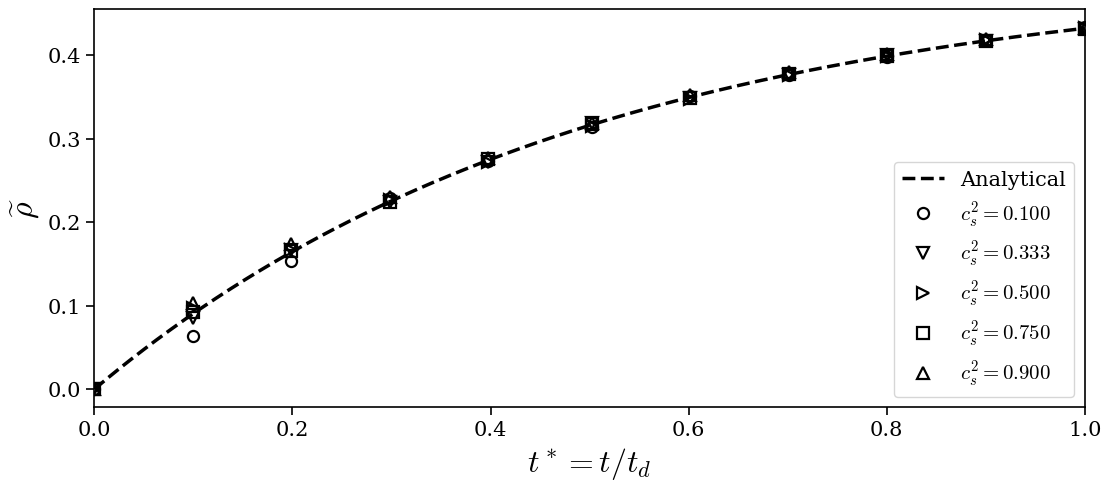

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import time

# -------------------------- Configuration --------------------------
Nx = Ny = 129
rho0 = 1.0
u0 = 2.0**(-4)
Re = 100.0

# Lattice units: dx = dt = 1
Lx = float(Nx)
Ly = float(Ny)

nu = u0 * Lx / Re
lambda_x = 2.0 * np.pi / Lx
lambda_y = 2.0 * np.pi / Ly

td = 1.0 / (nu * (lambda_x**2 + lambda_y**2))

tstar_end = 1.0
nsteps = int(np.ceil(tstar_end * td))
sample_every = max(1, nsteps // 200)

# Modify this list to select the sound speeds to compare.
cs2_values = [0.1,1.0 / 3.0, 0.5, 0.75, 0.9]

# ------------------------- D2Q9 velocities ------------------------
cx = np.array([0, 1, 0, -1, 0, 1, -1, -1, 1], dtype=int)
cy = np.array([0, 0, 1, 0, -1, 1, 1, -1, -1], dtype=int)

CX = cx[:, None, None]
CY = cy[:, None, None]

x = np.arange(Nx, dtype=float) + 0.5
y = np.arange(Ny, dtype=float) + 0.5
X, Y = np.meshgrid(x, y, indexing="ij")

# This benchmark uses a square domain.
assert Nx == Ny

# ------------------------- Simulation -----------------------------
def run_taylor_green(cs2):
    if not 0.0 < cs2 < 1.0:
        raise ValueError("Require 0 < cs² < 1.")

    cs = np.sqrt(cs2)
    # tau = 0.5 + nu / cs2
    # Match the viscosity governing this square Taylor–Green vortex.
    tau = 0.5 + 2.0 * nu / (1.0 - cs2)

    # Variable weights: each axis/diagonal velocity has this weight.
    w0 = (1.0 - cs2)**2
    w1 = cs2 * (1.0 - cs2) / 2.0
    w2 = cs2**2 / 4.0

    w = np.array([w0] + [w1]*4 + [w2]*4)
    W = w[:, None, None]

    def equilibrium(rho, ux, uy):
        return W * rho * (
            1.0
            + (CX*ux + CY*uy) / cs2
            + (
                ux**2 * (CX**2 - cs2)
                + uy**2 * (CY**2 - cs2)
            ) / (cs2 * (1.0 - cs2))
            + ux*uy*CX*CY / cs2**2
        )

    # Initial fields from the supplied benchmark
    ux = (
        -u0 * np.sqrt(Ly / Lx)
        * np.cos(lambda_x * X)
        * np.sin(lambda_y * Y)
    )

    uy = (
        u0 * np.sqrt(Lx / Ly)
        * np.sin(lambda_x * X)
        * np.cos(lambda_y * Y)
    )

    pressure_shape = (
        (Ly / Lx) * np.cos(2.0 * lambda_x * X)
        + (Lx / Ly) * np.cos(2.0 * lambda_y * Y)
    )

    rho = rho0 - rho0 * u0**2 / (4.0 * cs2) * pressure_shape

    if np.any(rho <= 0.0):
        raise ValueError("Nonpositive initial density.")

    # Fixed initial normalization: do not update inside the loop.
    rho_max_initial = rho.max()
    rho_min_initial = rho.min()
    density_range_initial = rho_max_initial - rho_min_initial
    mass_initial = rho.sum()

    f = equilibrium(rho, ux, uy)
    fp = np.empty_like(f)

    history = {
        "tstar": [0.0],
        "rho_tilde": [0.0],
        "mass_error": [0.0],
    }

    stable = True
    start = time.perf_counter()

    print(
        f"cs²={cs2:.6f}, Ma0={u0/cs:.6f}, "
        f"tau={tau:.6f}, td={td:.3f}, steps={nsteps}"
    )

    for step in range(1, nsteps + 1):
        # Collision
        feq = equilibrium(rho, ux, uy)
        fp[:] = f - (f - feq) / tau

        # Periodic streaming
        for k in range(9):
            f[k] = np.roll(
                fp[k],
                shift=(int(cx[k]), int(cy[k])),
                axis=(0, 1)
            )

        # Macroscopic fields
        rho = f.sum(axis=0)

        if not np.all(np.isfinite(f)) or np.any(rho <= 0.0):
            print(f"  Stopped: invalid state at step {step}.")
            stable = False
            break

        ux = np.einsum("i,ixy->xy", cx, f) / rho
        uy = np.einsum("i,ixy->xy", cy, f) / rho

        if step % sample_every == 0 or step == nsteps:
            history["tstar"].append(step / td)

            history["rho_tilde"].append(
                (rho_max_initial - rho.max())
                / density_range_initial
            )

            history["mass_error"].append(
                abs(rho.sum() - mass_initial) / mass_initial
            )

    result = {
        key: np.asarray(values)
        for key, values in history.items()
    }
    result["cs2"] = cs2
    result["stable"] = stable

    print(
        f"  elapsed={time.perf_counter() - start:.2f} s, "
        f"max relative mass error="
        f"{result['mass_error'].max():.3e}"
    )

    return result

# ------------------------ Run all cases ---------------------------
results = [run_taylor_green(cs2) for cs2 in cs2_values]

# ----------------------------- Plot -------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 15,
    "axes.labelsize": 23,
    "legend.fontsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
})

fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)

# Analytical solution using the prescribed viscosity
tstar_exact = np.linspace(0.0, tstar_end, 400)
rho_tilde_exact = 0.5 * (1.0 - np.exp(-2.0 * tstar_exact))

ax.plot(
    tstar_exact,
    rho_tilde_exact,
    "k--",
    linewidth=2.5,
    label="Analytical",
)

markers = ["o", "v", ">", "s", "^", "D"]

# Actual numerical results
for j, result in enumerate(results):
    number = min(11, len(result["tstar"]))
    indices = np.unique(
        np.linspace(
            0, len(result["tstar"]) - 1,
            number, dtype=int
        )
    )

    label = rf"$c_s^2={result['cs2']:.3f}$"
    if not result["stable"]:
        label += " (stopped)"

    ax.plot(
        result["tstar"][indices],
        result["rho_tilde"][indices],
        linestyle="none",
        marker=markers[j % len(markers)],
        markersize=8,
        markerfacecolor="none",
        markeredgecolor="black",
        markeredgewidth=1.6,
        label=label,
    )

    # Error evaluated at the recorded simulation times
    reference = 0.5 * (
        1.0 - np.exp(-2.0 * result["tstar"])
    )
    max_error = np.max(
        np.abs(result["rho_tilde"] - reference)
    )

    print(
        f"cs²={result['cs2']:.6f}: "
        f"max absolute density-diagnostic error={max_error:.6e}"
    )

ax.set_xlabel(r"$t^*=t/t_d$")
ax.set_ylabel(r"$\widetilde{\rho}$")
ax.set_xlim(0.0, tstar_end)

ax.tick_params(direction="out", width=1.2, length=6)
ax.legend(loc="best", frameon=True)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.show()